# Chapter 29: Mechanism Design, Revelation, and Implementation

This notebook reruns four worked examples from the chapter: the gains a posted price cannot reach (Myerson-Satterthwaite), how fixed weights change an affine maximizer's choice (Roberts), why the quadratic score rewards an honest forecast, and VCG payments as displaced alternatives. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def posted_price_gains(values, costs, p):
    """Expected gains from trade at a posted price p with equally likely, independent types
    (myerson-satterthwaite-theorem, ch029). Trade happens when value >= p >= cost.

    Book: values (50, 100), costs (20, 70): first best 35; p = 60 -> 20; p = 40 or 80 -> 27.5.
    Returns {"first_best", "gains", "shortfall", "trades": [(v, c, gain, trades_at_p)]}.
    """
    n = len(values) * len(costs)
    rows, fb, g = [], 0.0, 0.0
    for v in values:
        for c in costs:
            gain = max(v - c, 0.0)
            ok = v >= p >= c
            fb += gain
            g += (v - c) if ok else 0.0
            rows.append((v, c, gain, ok))
    return {"first_best": fb / n, "gains": g / n, "shortfall": (fb - g) / n, "trades": rows}


def affine_score(values, weights, kappa):
    """Affine-maximizer scores S_k = sum_i w_i v_i(k) + kappa_k (roberts-affine-maximizer-theorem, ch029).

    ``values`` is a list of per-agent value lists over alternatives. Book: vA (90, 55, 0),
    vB (25, 70, 0), kappa (-60, -50, 0), w (1, 1.5) -> (67.5, 110, 0); w_B = 0.5 -> (42.5, 40, 0).
    Returns the list of scores.
    """
    return [sum(w * v[k] for w, v in zip(weights, values)) + kappa[k] for k in range(len(kappa))]


def expected_score(p, q, rule="quadratic"):
    """Expected score of report q under belief p (strictly-proper-scoring-rules, ch029).

    quadratic: S(q, Y) = 1 - (q - Y)^2; linear: S(q, Y) = Yq + (1 - Y)(1 - q).
    Book: p = 0.65 -> quadratic 0.7725 at q = 0.65, 0.75 at 0.5 and 0.8; linear 0.35 + 0.30q.
    """
    if rule == "quadratic":
        return p * (1 - (q - 1) ** 2) + (1 - p) * (1 - q ** 2)
    if rule == "linear":
        return p * q + (1 - p) * (1 - q)
    raise ValueError(rule)


def _best_allocation(bids, exclude=None):
    """Welfare-maximizing set of single-minded bids with disjoint packages (brute force)."""
    import itertools
    names = [n for n in bids if n != exclude]
    best, best_set = 0.0, ()
    for k in range(1, len(names) + 1):
        for combo in itertools.combinations(names, k):
            items = [i for n in combo for i in bids[n][0]]
            if len(items) != len(set(items)):
                continue
            w = sum(float(bids[n][1]) for n in combo)
            if w > best + 1e-12:
                best, best_set = w, combo
    return best, best_set


def vcg_payments(bids, packages=None):
    """VCG (Clarke pivot) payments for single-minded package bids.

    Principles: core-selecting-package-auctions (ch028), vickrey-clarke-groves-mechanism (ch029).
    ``bids`` maps bidder -> value; ``packages`` maps bidder -> iterable of items. (A bids dict of
    bidder -> (items, value) is also accepted with packages=None.) Payment of a winner i is
    W(without i) - (W - v_i). Book: Alice A 60, Ben B 60, Nora AB 100 -> locals win, pay 40 each,
    revenue 80; Nora 130 -> Nora wins, pays 120. ch029: X AB 140, Y A 80, Z B 75 -> pY 65, pZ 60;
    X 160 -> pX 155. Returns {"winners", "welfare", "payments", "revenue", "utilities"}.
    """
    if packages is not None:
        bids = {n: (tuple(packages[n]), float(v)) for n, v in bids.items()}
    welfare, winners = _best_allocation(bids)
    payments, utilities = {}, {}
    for n in winners:
        w_without, _ = _best_allocation(bids, exclude=n)
        payments[n] = w_without - (welfare - float(bids[n][1]))
        utilities[n] = float(bids[n][1]) - payments[n]
    return {"winners": list(winners), "welfare": welfare, "payments": payments,
            "revenue": sum(payments.values()), "utilities": utilities}


plt.rcParams.update(HOUSE_RC)


auctions = SimpleNamespace(posted_price_gains=posted_price_gains, affine_score=affine_score, expected_score=expected_score, vcg_payments=vcg_payments)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'myerson-satterthwaite-theorem': {'values': (50, 100),
                                   'costs': (20, 70),
                                   'first_best': 35,
                                   'price': 60,
                                   'gains_60': 20,
                                   'shortfall_60': 15,
                                   'gains_40': 27.5,
                                   'gains_80': 27.5},
 'roberts-affine-maximizer-theorem': {'vA': (90, 55, 0),
                                      'vB': (25, 70, 0),
                                      'kappa': (-60, -50, 0),
                                      'wA': 1,
                                      'wB': 1.5,
                                      'scores': (67.5, 110, 0),
                                      'wB_low': 0.5,
                                      'scores_low': (42.5, 40, 0)},
 'strictly-proper-scoring-rules': {'p': 0.65,
                                   'truth_score': 0.7725,
                                   'score_050': 0.75,
                                   'score_080': 0.75,
                                   'loss': 0.0225,
                                   'loss_dollars': 2.25,
                                   'linear_intercept': 0.35,
                                   'linear_slope': 0.3},
 'vickrey-clarke-groves-mechanism': {'x': 140,
                                     'y': 80,
                                     'z': 75,
                                     'value': 155,
                                     'pY': 65,
                                     'pZ': 60,
                                     'utility_each': 15,
                                     'revenue': 125,
                                     'x_cf': 160,
                                     'pX_cf': 155,
                                     'uX_cf': 5},
 'constructed': {'myerson-satterthwaite-theorem': {'price': [50]},
                 'roberts-affine-maximizer-theorem': {'wB': [1, 2]},
                 'strictly-proper-scoring-rules': {'q': [1.0]},
                 'vickrey-clarke-groves-mechanism': {'x': [130, 150], 'y': [90]}}}


def g(x):
    """Whole numbers without decimals, others with up to two: 27.5, 35, 0.556."""
    return num(x, 0) if float(x).is_integer() else f"{x:.2f}".rstrip("0").rstrip(".")


def posted_picture(p=60):
    b = BV["myerson-satterthwaite-theorem"]
    res = auctions.posted_price_gains(b["values"], b["costs"], p)
    rows = res["trades"]
    names = [f"({v}, {c})" for v, c, _, _ in rows]
    realized = [(v - c) if ok else 0 for v, c, _, ok in rows]
    fig, ax = new_figure()
    bar_compare(ax, names, realized, colors=["teal" if ok else "light" for *_, ok in rows],
                value_labels=[f"{g(r)} of {g(gain)}" for r, (_, _, gain, _) in zip(realized, rows)],
                ylabel="Gains from trade ($ thousand)", xlabel="Type pair (buyer value, seller cost)")
    ax.set_ylim(0, 100)
    traded = [f"({v}, {c})" for v, c, _, ok in rows if ok]
    missed = [f"({v}, {c})" for v, c, gain, ok in rows if gain > 0 and not ok]
    terms = " + ".join(g(r) for r in realized if r > 0)
    metrics = {"Pairs that trade": join_and(traded), "Efficient pairs lost": join_and(missed) or "none",
               "Expected gains at this price ($000)": g(res["gains"]),
               "First-best expected gains ($000)": g(res["first_best"]),
               "Shortfall ($000)": g(res["shortfall"])}
    interp = (f"At a posted price of {p}, a buyer accepts when its value is at least {p} and a seller when its cost "
              f"is at most {p}. Trade happens at {join_and(traded)}, so expected gains are 1/4 x ({terms}) = "
              f"{g(res['gains'])} thousand, against the first best 1/4 x (30 + 0 + 80 + 30) = 35. The price loses "
              f"{join_and(missed)}, a shortfall of 35 - {g(res['gains'])} = {g(res['shortfall'])}.")
    steps = [f"Trades at p = {p}: {join_and(traded)}", f"Gains = 1/4 x ({terms}) = {g(res['gains'])}",
             "First best = 1/4 x (30 + 0 + 80 + 30) = 35",
             f"Shortfall = 35 - {g(res['gains'])} = {g(res['shortfall'])}"]
    alt = (f"Four bars for the type pairs. At price {p} the pairs {join_and(traded)} trade; the efficient pairs "
           f"{join_and(missed)} do not. Expected gains are {g(res['gains'])} of 35.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def roberts_picture(wb=1.5):
    b = BV["roberts-affine-maximizer-theorem"]
    vA, vB, kappa = b["vA"], b["vB"], b["kappa"]
    s = auctions.affine_score([vA, vB], [1, wb], kappa)
    names = ["Flood defense F", "Grid G", "No project N"]
    k = max(range(3), key=lambda i: s[i])
    tie_w = (vA[0] + kappa[0] - vA[1] - kappa[1]) / (vB[1] - vB[0])
    fig, ax = new_figure()
    bar_compare(ax, names, s, colors=["teal" if i == k else "light" for i in range(3)],
                value_labels=[g(x) for x in s], ylabel="Affine score ($ million)", xlabel="Project")
    ax.set_ylim(0, 160)
    metrics = {"S_F": g(s[0]), "S_G": g(s[1]), "S_N": g(s[2]), "Choice": names[k],
               "Weight at which F and G tie": num(tie_w, 3)}
    interp = (f"With w_B = {g(wb)}, S_F = 90 + {g(wb)} x 25 - 60 = {g(s[0])} and S_G = 55 + {g(wb)} x 70 - 50 = "
              f"{g(s[1])}, while S_N = 0. The rule picks {names[k]}. F and G tie where 30 + 25w = 5 + 70w, so "
              f"w = 25/45 = {num(tie_w, 3)}; above that weight the grid wins.")
    steps = [f"S_F = 90 + {g(wb)} x 25 - 60 = {g(s[0])}", f"S_G = 55 + {g(wb)} x 70 - 50 = {g(s[1])}", "S_N = 0",
             f"Tie: 30 + 25w = 5 + 70w, w = 25 / 45 = {num(tie_w, 3)}"]
    alt = f"Three bars: S_F = {g(s[0])}, S_G = {g(s[1])}, S_N = 0. {names[k]} is highlighted as the choice."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def scoring_picture(q=0.65, rule="quadratic"):
    p = BV["strictly-proper-scoring-rules"]["p"]
    es = auctions.expected_score(p, q, rule)
    if rule == "quadratic":
        s1, s0 = 1 - (q - 1) ** 2, 1 - q ** 2
        best_q = p
    else:
        s1, s0 = q, 1 - q
        best_q = 1.0
    best = auctions.expected_score(p, best_q, rule)
    gap = best - es
    qs = np.linspace(0, 1, 101)
    fig, ax = new_figure()
    ax.plot(qs, [auctions.expected_score(p, x, rule) for x in qs], color=PALETTE["navy"], linewidth=2.2,
            label=f"expected {rule} score")
    ax.legend(loc="lower right", frameon=False)
    vline(ax, best_q, f"best report {g(best_q)}", col="gold", y_frac=0.97, ha="right")
    mark(ax, q, es, f"q = {g(q)}: {num(es, 4)}", col="teal", dx=-8, dy=-10, ha="right", va="top")
    ax.set_xlim(0, 1.04)
    ax.set_ylim(0.2, 1.05)
    ax.set_xlabel("Reported probability q")
    ax.set_ylabel("Expected score (hundreds of $)")
    metrics = {"Score if the event occurs": num(s1, 4), "Score if it does not": num(s0, 4),
               "Expected score": num(es, 4), "Best report under this rule": g(best_q),
               "Shortfall from the best report": num(gap, 4)}
    interp = (f"Under the {rule} rule with belief 0.65, a report of {g(q)} scores {num(s1, 4)} if the event occurs and "
              f"{num(s0, 4)} if not, so the expected score is 0.65 x {num(s1, 4)} + 0.35 x {num(s0, 4)} = {num(es, 4)}. "
              + ("The quadratic rule peaks at the true belief 0.65, so honesty is optimal"
                 if rule == "quadratic" else
                 "The linear rule's expected score 0.35 + 0.30q rises with q, so it rewards reporting 1")
              + (f"; this report is the best one." if gap < 1e-12 else
                 f"; this report falls {num(gap, 4)} short of the best ({num(best, 4)})."))
    steps = [f"S(q, 1) = {num(s1, 4)}, S(q, 0) = {num(s0, 4)}",
             f"E[S] = 0.65 x {num(s1, 4)} + 0.35 x {num(s0, 4)} = {num(es, 4)}",
             f"Best report {g(best_q)}: {num(best, 4)}, gap {num(best, 4)} - {num(es, 4)} = {num(gap, 4)}"]
    alt = (f"Expected {rule} score against the report q for belief 0.65; it peaks at {g(best_q)}. The current report "
           f"{g(q)} scores {num(es, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def vcg_picture(x=140, y=80):
    z = BV["vickrey-clarke-groves-mechanism"]["z"]
    res = auctions.vcg_payments({"X": x, "Y": y, "Z": z}, {"X": ["A", "B"], "Y": ["A"], "Z": ["B"]})
    pay, util = res["payments"], res["utilities"]
    fig, ax = new_figure()
    if "X" in res["winners"]:
        names, vals = ["X pays", "X utility", "Revenue", "Value"], [pay["X"], util["X"], res["revenue"], res["welfare"]]
        metrics = {"Winners": "X (both windows)", "Payments": f"X {num(pay['X'], 0)}",
                   "Utilities": f"X {num(util['X'], 0)}", "Revenue": num(res["revenue"], 0),
                   "Allocation value": num(res["welfare"], 0)}
        interp = (f"X's {x} exceeds Y and Z's {y} + {z} = {y + z}, so X wins both windows. Without X, Y and Z would "
                  f"create {y + z}; in X's allocation they get 0, so X pays {y + z} - 0 = {num(pay['X'], 0)} and keeps "
                  f"{x} - {num(pay['X'], 0)} = {num(util['X'], 0)}.")
        steps = [f"{x} > {y} + {z} = {y + z}", f"p_X = {y + z} - 0 = {num(pay['X'], 0)}",
                 f"u_X = {x} - {num(pay['X'], 0)} = {num(util['X'], 0)}"]
    else:
        names = ["Y pays", "Z pays", "Revenue", "Value"]
        vals = [pay["Y"], pay["Z"], res["revenue"], res["welfare"]]
        metrics = {"Winners": "Y (window A) and Z (window B)",
                   "Payments": f"Y {num(pay['Y'], 0)}, Z {num(pay['Z'], 0)}",
                   "Utilities": f"Y {num(util['Y'], 0)}, Z {num(util['Z'], 0)}",
                   "Revenue": num(res["revenue"], 0), "Allocation value": num(res["welfare"], 0)}
        interp = (f"Y and Z create {y} + {z} = {y + z}, more than X's {x}, so they win. Removing Y makes X's {x} the "
                  f"best alternative, and Z gets {z} in the chosen allocation, so p_Y = {x} - {z} = {num(pay['Y'], 0)}. "
                  f"Likewise p_Z = {x} - {y} = {num(pay['Z'], 0)}. Utilities are {y} - {num(pay['Y'], 0)} = "
                  f"{num(util['Y'], 0)} and {z} - {num(pay['Z'], 0)} = {num(util['Z'], 0)}; revenue "
                  f"{num(pay['Y'], 0)} + {num(pay['Z'], 0)} = {num(res['revenue'], 0)} against value {y + z}.")
        steps = [f"{y} + {z} = {y + z} > {x}", f"p_Y = {x} - {z} = {num(pay['Y'], 0)}",
                 f"p_Z = {x} - {y} = {num(pay['Z'], 0)}",
                 f"Revenue = {num(pay['Y'], 0)} + {num(pay['Z'], 0)} = {num(res['revenue'], 0)}"]
    bar_compare(ax, names, vals, colors=["navy", "teal", "gold", "light"], value_labels=[num(v, 0) for v in vals],
                ylabel="$ thousand", xlabel="Outcome")
    ax.set_ylim(0, 200)
    alt = "Bars: " + ", ".join(f"{n} {num(v, 0)}" for n, v in zip(names, vals)) + "."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Myerson-Satterthwaite: no posted price captures every gain from trade

Buyer value 50 or 100, seller cost 20 or 70 (thousand dollars), all four pairs equally likely.

$$\frac14(30+0+80+30)=35, \qquad \frac14(80)=20, \qquad \frac14(30+80)=27.5$$

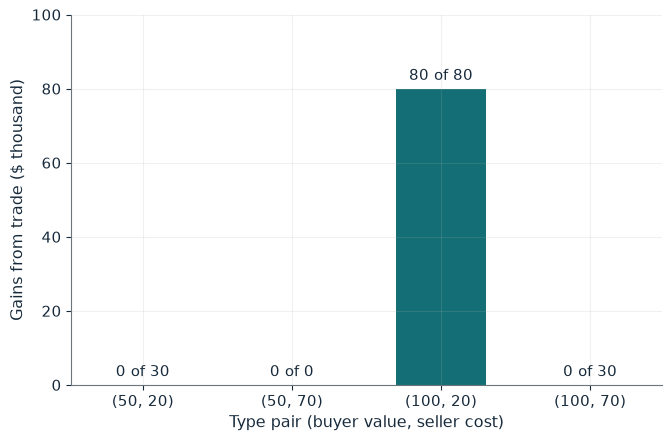

Pairs that trade                     (100, 20)
Efficient pairs lost                 (50, 20) and (100, 70)
Expected gains at this price ($000)  20
First-best expected gains ($000)     35
Shortfall ($000)                     15

Worked steps:
  1. Trades at p = 60: (100, 20)
  2. Gains = 1/4 x (80) = 20
  3. First best = 1/4 x (30 + 0 + 80 + 30) = 35
  4. Shortfall = 35 - 20 = 15

At a posted price of 60, a buyer accepts when its value is at least 60 and a seller when its cost is at most 60. Trade happens at (100, 20), so expected gains are 1/4 x (80) = 20 thousand, against the first best 1/4 x (30 + 0 + 80 + 30) = 35. The price loses (50, 20) and (100, 70), a shortfall of 35 - 20 = 15.


In [2]:
show(posted_picture(p=60))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(posted_picture, 'p', [40, 50, 60, 80], {}, ['Pairs that trade', 'Expected gains at this price ($000)', 'Shortfall ($000)'])

p | Pairs that trade | Expected gains at this price ($000) | Shortfall ($000)
40 | (50, 20) and (100, 20) | 27.5 | 7.5
50 | (50, 20) and (100, 20) | 27.5 | 7.5
60 | (100, 20) | 20 | 15
80 | (100, 20) and (100, 70) | 27.5 | 7.5


A price of 60 trades only at (100, 20), for 20 of the 35 available. The best prices reach 27.5; every price loses at least one efficient pair.

## 2. Roberts affine maximizer: weights change which project wins

$$S_F=90+1.5(25)-60=67.5, \qquad S_G=55+1.5(70)-50=110, \qquad S_N=0$$

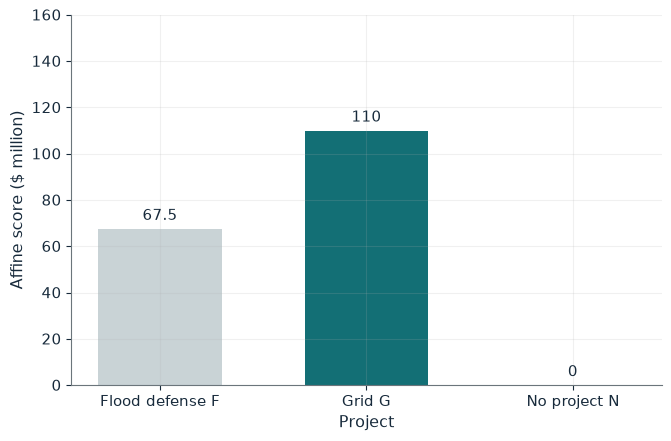

S_F                          67.5
S_G                          110
S_N                          0
Choice                       Grid G
Weight at which F and G tie  0.556

Worked steps:
  1. S_F = 90 + 1.5 x 25 - 60 = 67.5
  2. S_G = 55 + 1.5 x 70 - 50 = 110
  3. S_N = 0
  4. Tie: 30 + 25w = 5 + 70w, w = 25 / 45 = 0.556

With w_B = 1.5, S_F = 90 + 1.5 x 25 - 60 = 67.5 and S_G = 55 + 1.5 x 70 - 50 = 110, while S_N = 0. The rule picks Grid G. F and G tie where 30 + 25w = 5 + 70w, so w = 25/45 = 0.556; above that weight the grid wins.


In [4]:
show(roberts_picture(wb=1.5))

Change one input, `wb`, and hold the others at the book's values:

In [5]:
sweep(roberts_picture, 'wb', [0.5, 1, 1.5, 2], {}, ['S_F', 'S_G', 'Choice'])

wb | S_F | S_G | Choice
0.5 | 42.5 | 40 | Flood defense F
1 | 55 | 75 | Grid G
1.5 | 67.5 | 110 | Grid G
2 | 80 | 145 | Grid G


At w_B = 1.5 the grid wins 110 to 67.5; at 0.5 flood defense wins 42.5 to 40. The switch happens at w_B = 25/45 = 0.556.

## 3. Strictly proper scoring rules: quadratic rewards honesty, linear rewards bravado

Belief p = 0.65; quadratic score $S(q,Y)=1-(q-Y)^2$, linear score $S(q,Y)=Yq+(1-Y)(1-q)$.

$$0.65(0.8775)+0.35(0.5775)=0.7725, \qquad 0.65q+0.35(1-q)=0.35+0.30q$$

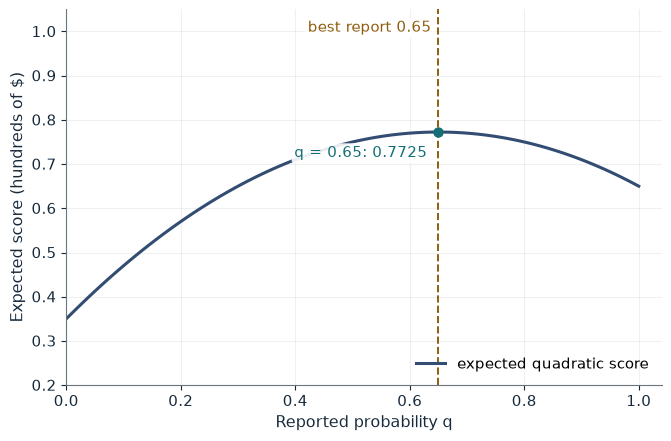

Score if the event occurs       0.8775
Score if it does not            0.5775
Expected score                  0.7725
Best report under this rule     0.65
Shortfall from the best report  0.0000

Worked steps:
  1. S(q, 1) = 0.8775, S(q, 0) = 0.5775
  2. E[S] = 0.65 x 0.8775 + 0.35 x 0.5775 = 0.7725
  3. Best report 0.65: 0.7725, gap 0.7725 - 0.7725 = 0.0000

Under the quadratic rule with belief 0.65, a report of 0.65 scores 0.8775 if the event occurs and 0.5775 if not, so the expected score is 0.65 x 0.8775 + 0.35 x 0.5775 = 0.7725. The quadratic rule peaks at the true belief 0.65, so honesty is optimal; this report is the best one.


In [6]:
show(scoring_picture(q=0.65, rule='quadratic'))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(scoring_picture, 'q', [0.5, 0.65, 0.8, 1.0], {'rule': 'linear'}, ['Expected score', 'Shortfall from the best report'])

q | Expected score | Shortfall from the best report
0.5 | 0.5000 | 0.1500
0.65 | 0.5450 | 0.1050
0.8 | 0.5900 | 0.0600
1.0 | 0.6500 | 0.0000


The quadratic score peaks at the true 0.65 with 0.7725; reports of 0.5 and 0.8 lose 0.0225 each. Under the linear rule the score rises with q, so reporting 1 is best.

## 4. Vickrey-Clarke-Groves: payments are displaced alternatives

X values windows A and B together at 140, Y values A at 80, Z values B at 75 (thousand dollars).

$$80+75=155>140, \qquad p_Y=140-75=65, \qquad p_Z=140-80=60$$

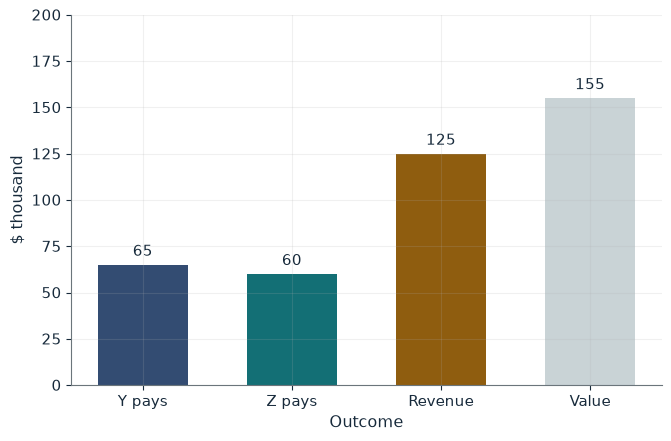

Winners           Y (window A) and Z (window B)
Payments          Y 65, Z 60
Utilities         Y 15, Z 15
Revenue           125
Allocation value  155

Worked steps:
  1. 80 + 75 = 155 > 140
  2. p_Y = 140 - 75 = 65
  3. p_Z = 140 - 80 = 60
  4. Revenue = 65 + 60 = 125

Y and Z create 80 + 75 = 155, more than X's 140, so they win. Removing Y makes X's 140 the best alternative, and Z gets 75 in the chosen allocation, so p_Y = 140 - 75 = 65. Likewise p_Z = 140 - 80 = 60. Utilities are 80 - 65 = 15 and 75 - 60 = 15; revenue 65 + 60 = 125 against value 155.


In [8]:
show(vcg_picture(x=140, y=80))

Change one input, `x`, and hold the others at the book's values:

In [9]:
sweep(vcg_picture, 'x', [130, 140, 150, 160], {'y': 80}, ['Winners', 'Payments', 'Revenue'])

x | Winners | Payments | Revenue
130 | Y (window A) and Z (window B) | Y 55, Z 50 | 105
140 | Y (window A) and Z (window B) | Y 65, Z 60 | 125
150 | Y (window A) and Z (window B) | Y 75, Z 70 | 145
160 | X (both windows) | X 155 | 155


Y and Z win and pay 65 and 60, the value their presence takes from X. When X bids 160 it wins and pays 155, what Y and Z could have made together.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

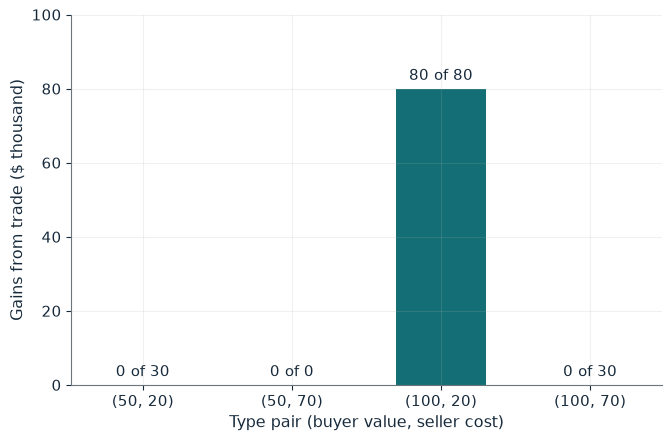

Pairs that trade                     (100, 20)
Efficient pairs lost                 (50, 20) and (100, 70)
Expected gains at this price ($000)  20
First-best expected gains ($000)     35
Shortfall ($000)                     15

Worked steps:
  1. Trades at p = 60: (100, 20)
  2. Gains = 1/4 x (80) = 20
  3. First best = 1/4 x (30 + 0 + 80 + 30) = 35
  4. Shortfall = 35 - 20 = 15

At a posted price of 60, a buyer accepts when its value is at least 60 and a seller when its cost is at most 60. Trade happens at (100, 20), so expected gains are 1/4 x (80) = 20 thousand, against the first best 1/4 x (30 + 0 + 80 + 30) = 35. The price loses (50, 20) and (100, 70), a shortfall of 35 - 20 = 15.


In [10]:
show(posted_picture(p=60))

## Practice

**1.** At a posted price of 50, which pairs trade and what are expected gains?

<details><summary>Answer</summary>

(50, 20) and (100, 20): 1/4 x (30 + 80) = 27.5, a shortfall of 7.5.

</details>

**2.** Under the quadratic rule, what is the expected score of reporting 1?

<details><summary>Answer</summary>

0.65 x 1 + 0.35 x 0 = 0.65, which is 0.1225 = 0.35 x 0.35 below the truthful 0.7725.

</details>

**3.** With x = 160 and y = 90, who wins and what are the VCG payments?

<details><summary>Answer</summary>

90 + 75 = 165 > 160, so Y and Z win; p_Y = 160 - 75 = 85 and p_Z = 160 - 90 = 70; revenue 155.

</details>